# Statlog Landsat Satellite 
IN3062 Introduction to Artificial Intelligence, Group 28

# Data Exploration and Preprocessing
The purpose of this section is to investigate the characteristics
of the Statlog Landsat Satellite dataset (Srinivasan, 1993) and identify any preprocessing required
before applying artificial intelligence techniques.

## 1. Dataset Loading

The Landsat dataset is loaded using pandas (pandas, 2026). The training file (sat.trn) contains whitespace separated values without column headings (Srinivasan, 1993). The supplied training dataset will be used for exploratory analysis and model development.

In [1]:
import os
import pandas as pd

# File loading approach adapted from IN3062 Tutorial 1 solutions (Howe, 2026).
# Whitespace separator learned from GeeksforGeeks (2024).
# Header parameter learned from pandas documentation (pandas, 2026).

# Defines the directory and creates the file path to the training dataset
path = "statlog"
filename_read = os.path.join(path, "sat.trn")

# Loads the dataset, using whitespace as the column separator 
# Assigns default numeric column headers since the file has no header row
df = pd.read_csv(filename_read, sep=r"\s+", header=None)

# Prints the dataset
print("Full Statlog dataset:")
print(df)

Full Statlog dataset:
      0    1    2   3   4    5    6   7   8    9   ...   27  28   29   30  \
0     92  115  120  94  84  102  106  79  84  102  ...  104  88  121  128   
1     84  102  106  79  84  102  102  83  80  102  ...  100  84  107  113   
2     84  102  102  83  80  102  102  79  84   94  ...   87  84   99  104   
3     80  102  102  79  84   94  102  79  80   94  ...   79  84   99  104   
4     84   94  102  79  80   94   98  76  80  102  ...   79  84  103  104   
...   ..  ...  ...  ..  ..  ...  ...  ..  ..  ...  ...  ...  ..  ...  ...   
4430  56   64  108  96  64   71  108  96  68   75  ...   92  66   83  108   
4431  64   71  108  96  68   75  108  96  71   87  ...   96  66   87  104   
4432  68   75  108  96  71   87  108  88  71   91  ...   89  63   87  104   
4433  71   87  108  88  71   91  100  81  76   95  ...   89  70  100  104   
4434  71   91  100  81  76   95  108  88  80   95  ...   85  70   91  104   

       31  32   33   34  35  36  
0     100  84  107 

The training dataset was successfully loaded, containing 4435 observations and 37 columns.

## 2. Initial Dataset Inspection
The first five observations and dataset dimensions are
examined to confirm that the data has been loaded correctly.
The input features and target labels are then separated
for analysis and classification.

In [2]:
# Row inspection learned from IN3062 Tutorial 1 (Howe, 2026).
# Shape inspection learned from IN3062 Tutorial 2, Part 1 (Howe, 2026).

# Displays the first five observations
print("The first five observations:")
print(df[:5])

# Displays the number of rows and columns
print("\nThe number of rows and columns:")
print(df.shape)

The first five observations:
   0    1    2   3   4    5    6   7   8    9   ...   27  28   29   30   31  \
0  92  115  120  94  84  102  106  79  84  102  ...  104  88  121  128  100   
1  84  102  106  79  84  102  102  83  80  102  ...  100  84  107  113   87   
2  84  102  102  83  80  102  102  79  84   94  ...   87  84   99  104   79   
3  80  102  102  79  84   94  102  79  80   94  ...   79  84   99  104   79   
4  84   94  102  79  80   94   98  76  80  102  ...   79  84  103  104   79   

   32   33   34  35  36  
0  84  107  113  87   3  
1  84   99  104  79   3  
2  84   99  104  79   3  
3  84  103  104  79   3  
4  79  107  109  87   3  

[5 rows x 37 columns]

The number of rows and columns:
(4435, 37)


In [3]:
# Feature and target separation learned from IN3062 Tutorial 2, Part 1 (Howe, 2026).
# Column selection adapted for the Landsat dataset using pandas DataFrame method iloc (pandas, 2026).

# Separates input features and target labels
X = df.iloc[:, 0:36].values
Y = df.iloc[:, 36].values

# Displays the dimensions
print("Input Features:")
print(X.shape)
print("Target Labels:")
print(Y.shape)

Input Features:
(4435, 36)
Target Labels:
(4435,)


The training dataset contains 36 numerical input features
and one target variable. The input features represent four
spectral measurements for each of nine pixels in a 3 x 3
neighbourhood.

The feature matrix (X) contains 4435 rows and 36 columns,
while the target array (Y) contains 4435 class labels.

The classification task is to predict the land-cover class
of the central pixel.

## 3. Data Quality Checks
The data types, missing values and duplicate observations
are investigated to determine whether data cleaning is
required before model development.

In [4]:
# Data type, missing value count and duplicate checks use pandas DataFrame methods (pandas, 2026).
# Combined data types and missing value counts into one table following the approach demonstrated 
# in IN3062 regDiabetes.py, other solution to exercises 3 (Howe, 2026).

# Combines data types and missing value counts into one table 
data_quality = pd.DataFrame({ "Data type:": df.dtypes, "Missing values:": df.isnull().sum() }) 
print(data_quality)

# Counts duplicate observations
print("\nDuplication count:")
print(df.duplicated().sum())

   Data type:  Missing values:
0       int64                0
1       int64                0
2       int64                0
3       int64                0
4       int64                0
5       int64                0
6       int64                0
7       int64                0
8       int64                0
9       int64                0
10      int64                0
11      int64                0
12      int64                0
13      int64                0
14      int64                0
15      int64                0
16      int64                0
17      int64                0
18      int64                0
19      int64                0
20      int64                0
21      int64                0
22      int64                0
23      int64                0
24      int64                0
25      int64                0
26      int64                0
27      int64                0
28      int64                0
29      int64                0
30      int64                0
31      

### Findings

All 37 columns contain integer values (int64), including
the 36 numerical features and the target class labels.

No missing values or duplicate observations were
identified in the training dataset. Therefore, missing value imputation and removing duplicates are not required.

As all input features are numerical, categorical feature
encoding is also unnecessary. However, further investigation
is required to determine whether numerical transformations,
such as standardisation, would be beneficial.

## 4. Class Distribution
The number and percentage of observations belonging to each
land-cover class are calculated to investigate potential
class imbalance within the training dataset.

In [5]:
# Class frequencies calculated using pandas Series methods (pandas, 2026).

# Counts the number of observations in each class
class_counts = df[36].value_counts().sort_index()

print("Number of observations in each class:")
print(class_counts)

# Calculates the percentage of observations in each class
class_percentages = (class_counts / len(df)) * 100

print("\nThe percentage of observations in each class:")
print(class_percentages.round(3))

Number of observations in each class:
36
1    1072
2     479
3     961
4     415
5     470
7    1038
Name: count, dtype: int64

The percentage of observations in each class:
36
1    24.171
2    10.800
3    21.669
4     9.357
5    10.598
7    23.405
Name: count, dtype: float64


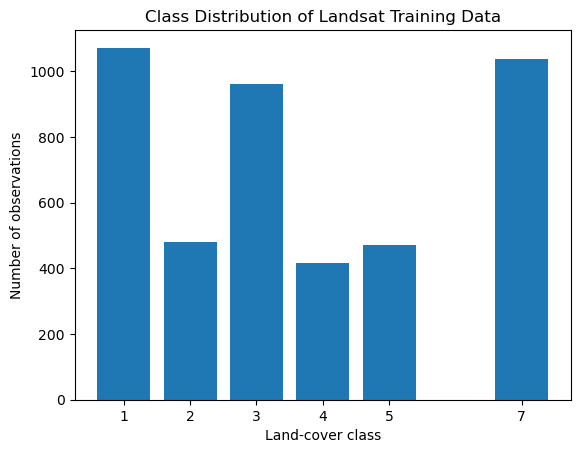

In [6]:
import matplotlib.pyplot as plt

# Plotting approach learned from IN3062 Tutorial 2, Part 1 (Howe, 2026).
# Plotting approach adapted from GeeksforGeeks (2024).

# Plots the number of observations in each land-cover class
plt.bar(class_counts.index, class_counts.values)

# Adds axis labels and the title to the chart
plt.xlabel("Land-cover class")
plt.ylabel("Number of observations")
plt.title("Class Distribution of Landsat Training Data")

# Sets the x-axis tick marks to match each class label and displays the plot
plt.xticks(class_counts.index)
plt.show()

*Figure 1: Class distribution of land-cover classes in the
Landsat training dataset.*

### Findings

The training dataset contains six classes with unequal
representation. Class 1 is the largest class, containing
1072 observations (24.17%), while class 4 is the smallest,
containing 415 observations (9.36%).

Class 1 contains approximately 2.58 times as many
observations as class 4. Classes 2, 4 and 5 are less
represented than classes 1, 3 and 7.

This imbalance may influence model performance, as models
could perform better on the more frequently represented
classes. However, further experiments are required to
determine whether this occurs.

Accuracy alone may not adequately reflect performance
across all classes. Therefore, macro-F1 and confusion
matrices will also be considered during model evaluation.

## 5. Numerical Feature Analysis

The numerical features are investigated to examine their
ranges, average values and variability. This analysis will
help identify whether feature transformations such as
standardisation may be needed.

In [7]:
# Statistical analysis approach adapted from IN3062 Tutorial 1 (Howe, 2026).
# Column selection adapted for the Landsat dataset using pandas DataFrame method iloc (pandas, 2026).
# Combined mean, variance and standard deviation into one table following the approach demonstrated 
# in IN3062 regDiabetes.py, other solution to exercises 3 (Howe, 2026).

# Selects the 36 input features, excluding the target column
features = df.iloc[:, 0:36]

# Combines mean, variance, and standard deviation of each feature into one table
feature_statistics = pd.DataFrame({ "Mean": features.mean(), "Variance": features.var(), "Standard deviation": features.std()})

print(feature_statistics.round(3))

      Mean  Variance  Standard deviation
0   69.474   186.313              13.650
1   83.855   516.429              22.725
2   99.323   277.961              16.672
3   82.556   349.520              18.695
4   69.209   183.668              13.552
5   83.499   520.379              22.812
6   99.175   276.477              16.628
7   82.480   350.224              18.714
8   68.963   182.192              13.498
9   83.131   520.447              22.813
10  98.974   278.104              16.676
11  82.414   355.069              18.843
12  69.375   186.523              13.657
13  83.732   519.217              22.786
14  99.413   278.508              16.689
15  82.654   353.521              18.802
16  69.127   183.906              13.561
17  83.434   520.647              22.818
18  99.242   279.775              16.726
19  82.618   355.092              18.844
20  68.920   181.322              13.466
21  83.145   521.017              22.826
22  99.004   279.553              16.720
23  82.480   358

### Findings

The feature means range from approximately 68.80 to 99.41,
while the standard deviations range from approximately
13.44 to 22.83.

The differences in standard deviation indicate that the
features have different levels of variability. This provides
a reason to investigate standardisation, particularly for
models that are sensitive to feature scales.

A repeating pattern is also observed in the feature
statistics across groups of four columns. This is consistent
with the dataset structure, where four spectral measurements
are recorded for each of nine neighbouring pixels.

The similarities between these groups suggest that further
investigation of feature relationships and potential
redundancy would be useful. Correlation analysis will be
conducted to examine these relationships.

## References:

GeeksforGeeks (2024) *How to read space-delimited files in pandas*. Available at: https://www.geeksforgeeks.org/pandas/how-to-read-space-delimited-files-in-pandas/ (Accessed: 20 November 2026).

GeeksforGeeks (2026) *Bar Plot in Matplotlib*. Available at: https://www.geeksforgeeks.org/pandas/bar-plot-in-matplotlib/ (Accessed: 21 November 2026).

Pandas (2026) *pandas.read_csv*. Available at: https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html (Accessed: 20 November 2026).

Pandas (2026) *pandas.DataFrame*. Available at: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html (Accessed: 20 November 2026).

Pandas (2026) *pandas.Series*. Available at: https://pandas.pydata.org/docs/reference/api/pandas.Series.html (Accessed: 20 November 2026).

Howe, J. (2026) 'ex1.ipynb' [Jupyter Notebook], *IN3062: Introduction to Artificial Intelligence*. Available at: https://moodle4.city.ac.uk/mod/resource/view.php?id=1343045 (Accessed: 19 November 2026).

Howe, J. (2026) 'ex1soln.py' [Python File], *IN3062: Introduction to Artificial Intelligence*. Available at: https://moodle4.city.ac.uk/mod/resource/view.php?id=1343046 (Accessed: 19 November 2026).

Howe, J. (2026) 'ex2Part1.ipynb' [Jupyter Notebook], *IN3062: Introduction to Artificial Intelligence*. Available at: https://moodle4.city.ac.uk/mod/resource/view.php?id=1343054 (Accessed: 19 November 2026).

Howe, J. (2026) 'regDiabetes.py' [Python File], *IN3062: Introduction to Artificial Intelligence*. Available at: https://moodle4.city.ac.uk/mod/resource/view.php?id=1343069 (Accessed: 21 November 2026).

Srinivasan, A. (1993) 'Statlog (Landsat Satellite)' [Dataset], *UCI Machine Learning Repository*. Available at: https://doi.org/10.24432/C55887 